# Robot interactions learned with EPDE

A pair of approaching robots can bounce, slide past one another, or have their motion constrained by a third robot. Two measurement windows answer different questions. A **40 ms window** measures the change across a contact. A **0.4 s window** measures where the pair goes after propulsion, turning and other encounters have also had time to act.

| Question | Data and measurement |
|---|---|
| What happens at contact? | Local clips from five 25 Hz swarm recordings. Compare measured relative velocity before and after the marked contact or a distance-threshold crossing. |
| How does a neighbor change a robot’s motion? | The same five recordings. Fit a vector correction to each robot’s next 0.4 s of motion, then evaluate the relative motion of close pairs. |
| What predicts approach and sliding in other experiments? | Three 50 Hz population sweeps. Predict both components of relative velocity over the next 0.4 s, with each experiment held out in turn. |

**Coordinate convention.** Freeze the line joining the two centers at the start of each measurement. The normal component lies along this line. Negative means approaching and positive means separating. The tangential component lies perpendicular to the line and retains its sign.

From the repository root, install the notebook environment with `python -m pip install -e . jupyterlab openpyxl`, then launch `python -m jupyterlab projects/robot/EPDE_robot_interactions.ipynb` and choose **Run All Cells**. The branch includes the five processed swarm tracks, the three population-sweep archives, and the result tables used below. The notebook includes its rendered plots and tables. It refits candidate equations, checks predictions against the archived scores, and runs three live EPDE searches for rebound, normal motion and sideways motion. Section 5 gives the mathematical definitions, a check against raw positions, and an analysis of both live pair fronts. R2 compares squared error with predicting the test-set mean. Higher is better, and a negative value means greater error than that reference. RMSE is in the units of the quantity being predicted. The equations below describe measured velocities.

**How EPDE results are reported here.** Each live search returns a Pareto front. Every returned equation receives its own coefficients, physical interpretation, training objectives, validation score and held-out evaluation. Historical single-equation summaries are labeled with the separate analysis rule used to produce them.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Locate the data from either the repository root or the notebook directory.
for parent in (Path.cwd(), *Path.cwd().parents):
    if (parent / "projects/robot/results/collision_transfer/pooled_law.json").is_file():
        root = parent
        break
else:
    raise FileNotFoundError("Open the notebook inside the EPDE checkout containing the robot results.")

robot = root / "projects/robot"
collision = robot / "results/collision_transfer"
pre = collision / "preprocessed"
rebound = pre / "restitution_epde"
video = pre / "video_rebound_verification"
normal = pre / "pair_normal"
sweeps = robot / "results/pair_interactions_sweeps/physical"
sys.path[:0] = [str(root), str(robot / "collision")]

def read_json(path):
    return json.loads(path.read_text(encoding="utf-8"))

calibration = read_json(robot / "collision/prospective/frozen_v1.json")
dt = calibration["horizon_frames"] / calibration["fps"]
diameter = calibration["cap_px"]
cutoff = calibration["cutoff_px"]
blue, orange, green, gray = "#21618A", "#B85229", "#007E74", "#58646B"
plt.rcParams.update({
    "figure.dpi": 110, "figure.figsize": (8.4, 3.7),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.axisbelow": True, "axes.titlelocation": "left",
    "font.size": 10, "legend.frameon": False,
})
print(f"25 Hz swarm series: diameter {diameter:.2f} px, neighbor cutoff {cutoff:.0f} px, forecast {dt:.1f} s.")

25 Hz swarm series: diameter 219.55 px, neighbor cutoff 253 px, forecast 0.4 s.


## 1. Watch the local reversal

The video review marks a single apparent contact frame. Select the quality-screened, arena-registered cases with an incoming approach and a 40 ms speed estimate. Selection uses the incoming sign and review labels. The outgoing sign is free to take either value.

For the left panel, take five **raw tracked** positions centered on each marked frame. Project both robots’ relative displacement onto the center line at that frame, then difference adjacent positions. Each trace has four velocities, plotted at their interval midpoints. The right panel uses the separately saved **arena-registered** before/after estimates with their reviewed timing brackets. These two measurements can differ for the same encounter. [Reviewed encounters](results/collision_transfer/preprocessed/video_rebound_verification/reviewed_encounters.csv) · [Velocity measurements](results/collision_transfer/preprocessed/video_rebound_verification/event_predictions.csv)

In [2]:
annotations = pd.read_csv(video / "reviewed_encounters.csv")
measured = pd.read_csv(video / "event_predictions.csv")
clips = measured.loc[
    measured["mode"].eq("arena_registered") & measured["quality_ok"]
    & measured["positions"].eq(2) & measured["incoming_px_s"].lt(0)
].merge(annotations, on=["recording", "case"], validate="one_to_one")
assert clips["review"].eq("single").all()

def contact_traces(clips):
    traces = []
    offsets = np.arange(-2, 3)
    for recording, cases in clips.groupby("recording"):
        with np.load(pre / f"{recording}.npz") as track:
            frames, ids = track["frame"], track["ids"].tolist()
            points, flags = track["raw_pos"], track["quality_flags"]
            fps = float(track["fps"])
            for case in cases.itertuples():
                wanted = int(case.contact) + offsets
                assert case.lo <= wanted[0] and wanted[-1] <= case.hi
                rows = np.searchsorted(frames, wanted)
                np.testing.assert_array_equal(frames[rows], wanted)
                i, j = ids.index(case.i), ids.index(case.j)
                assert not flags[rows][:, [i, j]].any() and fps == 25
                relative = points[rows, j] - points[rows, i]
                axis = relative[2] / np.linalg.norm(relative[2])
                traces.append(np.diff(relative @ axis) * fps)
    return np.stack(traces)

traces = contact_traces(clips)
closing = -clips["incoming_px_s"]
outgoing = clips["outgoing_px_s"]
# Give each recording equal total weight, as in the archived joint fit.
weight = 1 / clips.groupby("recording")["case"].transform("size")
e = (weight * closing * outgoing).sum() / (weight * closing**2).sum()
joint = pd.read_csv(video / "joint/summary.csv").query("cohort == 'video_40ms'").set_index("model")
np.testing.assert_allclose(e, joint.loc["restitution", "all_data_slope"])
print(f"{len(clips)} screened clips in {clips.recording.nunique()} recordings. Pooled slope e = {e:.3f}.")
print("Median raw normal speeds (px/s):", np.round(np.median(traces, axis=0), 1))

18 screened clips in 5 recordings. Pooled slope e = 0.710.
Median raw normal speeds (px/s): [-203.2 -204.2  248.5  143.6]


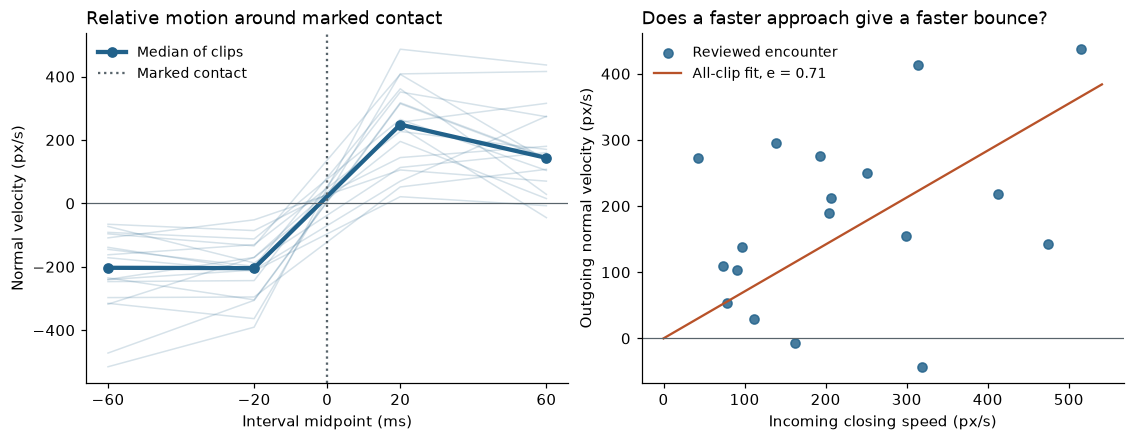

,events,recordings,Held-out RMSE (px/s),Held-out R2
model,,,,
restitution,18,5,135.738,-0.093
constant,18,5,136.624,-0.107
affine,18,5,133.965,-0.065


In [3]:
fig, (ax, scatter) = plt.subplots(1, 2, figsize=(10.2, 3.9), layout="constrained")
times = [-60, -20, 20, 60]
ax.plot(times, traces.T, color=blue, alpha=0.18, linewidth=1)
ax.plot(times, np.median(traces, axis=0), "o-", color=blue, lw=2.8, label="Median of clips")
ax.axvline(0, color=gray, ls=":", label="Marked contact")
ax.axhline(0, color=gray, lw=0.8)
ax.set(title="Relative motion around marked contact", xlabel="Interval midpoint (ms)",
       ylabel="Normal velocity (px/s)", xticks=[-60, -20, 0, 20, 60])
ax.legend(fontsize=9)

line_x = np.array([0, closing.max() * 1.05])
scatter.scatter(closing, outgoing, color=blue, alpha=0.83, label="Reviewed encounter")
scatter.plot(line_x, e * line_x, color=orange, label=f"All-clip fit, e = {e:.2f}")
scatter.axhline(0, color=gray, lw=0.8)
scatter.set(title="Does a faster approach give a faster bounce?",
            xlabel="Incoming closing speed (px/s)", ylabel="Outgoing normal velocity (px/s)")
scatter.legend(fontsize=9)
plt.show()

display(joint[["events", "recordings", "heldout_rmse", "heldout_r2"]].rename(columns={
    "heldout_rmse": "Held-out RMSE (px/s)", "heldout_r2": "Held-out R2"}).round(3))

The median normal velocity in consecutive 40 ms intervals was about **−203, −204, +249 and +144 px/s**. The sign changed across the marked frame and the outward speed was already smaller one interval later. These 18 selected clips establish a local reversal in this sample. Their pooled proportional fit gives `outgoing = 0.71 * closing`. Holding out a recording at a time gives 135.7 px/s RMSE for this rule and 136.6 px/s for a constant outgoing speed. The line in the scatterplot uses all clips for illustration. Predicting how hard any one pair will bounce remains difficult. [Joint fits and holdouts](results/collision_transfer/preprocessed/video_rebound_verification/joint/summary.csv)

## 2. Search for a rebound equation across many local encounters

For the larger search, detect an **entry** when the measured center distance crosses below one diameter, and a **release** when the distance reaches 1.03 diameters again. At 25 Hz, two positions give a 40 ms velocity. The incoming measurement ends before entry. The outgoing measurement starts either at entry or at release. The release analysis requires release within one second. Both measurements use the entry normal. A threshold crossing can fall a frame away from physical impact.

Each row below is one encounter. EPDE searches sums of up to four predictors including closing speed, squared closing speed, transverse speed, relative heading and combined spin. Candidate generation uses a balanced training screen. The first 75% of each of the other four recordings supplies the fit, their final 25% supplies validation scores, and the fifth recording supplies the test. The archived study also reported a single validation-minimum summary for each fold. [Event extraction and native search](collision/restitution_epde.py) · [Isolation and timing tests](results/collision_transfer/preprocessed/restitution_epde/report.md)

In [4]:
from restitution_epde import TERMS, screen, split as split_events

events = pd.read_csv(rebound / "events.csv.gz")
archive = pd.read_csv(rebound / "equations_by_fold.csv")
held = "N30_PWM10_D41"
train, valid, test = split_events(events, held, "loose", "release", 2, 0)

# Recover the structures native EPDE evaluated for this fold. The archive records
# eligibility after the training rank, amplitude and stability checks.
receipt = read_json(rebound / f"loose_release_{held}.json")
native_sets = {frozenset(item["terms"]) for item in receipt["evaluated"]}
eligible = archive.query(
    "held == @held and scope == 'loose' and target == 'release' and width == 2 and offset == 0 and eligible"
)
supports = [s.split("+") for s in eligible.terms if frozenset(s.split("+")) in native_sets]

def recording_weights(frame):
    return 1 / frame.groupby("recording")["entry"].transform("size").to_numpy()

def fit_candidate(terms):
    weights = np.sqrt(recording_weights(train))
    x = train[terms].to_numpy()
    beta = np.linalg.lstsq(x * weights[:, None], train.outgoing * weights, rcond=None)[0]
    error = valid.outgoing - valid[terms].to_numpy() @ beta
    valid_rmse = np.sqrt(np.average(error**2, weights=recording_weights(valid)))
    return valid_rmse, terms, beta

from IPython.display import Markdown

release_symbols = {
    "closing": "c", "closing_squared": r"\frac{c^2}{100}",
    "abs_tangent": r"\lvert u_t^-\rvert", "heading_n": "H_n", "spin_abs": r"S_\omega", "bias": "1",
}

def release_equation(coefficients):
    """Render the signed equation in the same units as the fit."""
    unknown = coefficients.keys() - release_symbols.keys()
    if unknown:
        raise KeyError(f"Missing mathematical definition for {unknown}")
    pieces = []
    for name, symbol in release_symbols.items():
        if name in coefficients:
            b = coefficients[name]
            sign = "-" if b < 0 else ("+" if pieces else "")
            factor = "" if name == "bias" else r"\," + symbol
            pieces.append(f"{sign}{abs(b):.4f}{factor}")
    return r"\widehat{u}_n^{\,\mathrm{rel}} = " + " ".join(pieces)

fits = [fit_candidate(s) for s in supports]
val_error, terms, beta = min(fits, key=lambda row: (row[0], len(row[1]), row[1]))
test_error = np.sqrt(np.mean((test.outgoing - test[terms].to_numpy() @ beta)**2))
archived_fit = eligible.loc[eligible.terms.eq("+".join(terms))].iloc[0]
np.testing.assert_allclose([val_error, test_error], [archived_fit.validation_rmse, archived_fit.rmse])
np.testing.assert_allclose(beta, [json.loads(archived_fit.coefficients)[k] for k in terms])
print(f"Holdout {held}: {len(train)} training, {len(valid)} validation, {len(test)} test events.")
display(Markdown("$$" + release_equation(dict(zip(terms, beta))) + "$$"))
print(f"Archival lowest-validation-RMSE comparison across {len(fits)} eligible native candidates. Held-out RMSE {test_error:.2f} px/s.")

Holdout N30_PWM10_D41: 459 training, 142 validation, 312 test events.


$$\widehat{u}_n^{\,\mathrm{rel}} = 0.5363\,c -0.0470\,\frac{c^2}{100} +24.8218\,H_n +0.0824\,S_\omega$$

Archival lowest-validation-RMSE comparison across 30 eligible native candidates. Held-out RMSE 134.06 px/s.


Let $k$ be the entry frame, $\ell$ the release frame and $\Delta t=0.04\,\mathrm{s}$. The relative position is $\mathbf r_m=\mathbf x_j[m]-\mathbf x_i[m]$. Fix $\mathbf n=\mathbf r_k/\lVert\mathbf r_k\rVert$ at entry and $\boldsymbol\tau=(-n_y,n_x)$. Write $\mathbf v^-=(\mathbf r_{k-1}-\mathbf r_{k-2})/\Delta t$. The measured target is $u_n^{\mathrm{rel}}=\mathbf n\cdot(\mathbf r_{\ell+1}-\mathbf r_\ell)/\Delta t$, in px/s. A positive value means separation along the entry normal.

| Search term | Mathematical definition | Measurement |
|---|---|---|
| <code>closing</code> | $c=-\mathbf v^-\cdot\mathbf n$ | Incoming closing speed in px/s. Only approaches with $c>0$ enter this search. |
| <code>closing_squared</code> | $c^2/100$ | The search squares the numerical speed in px/s and divides it by 100. |
| <code>abs_tangent</code> | $\lvert u_t^-\rvert=\lvert\mathbf v^-\cdot\boldsymbol\tau\rvert$ | Magnitude of the incoming sideways speed in px/s. |
| <code>heading_n</code> | $H_n=(\mathbf h_j-\mathbf h_i)\cdot\mathbf n$ | Relative heading along the entry normal, from $-2$ to $2$. For robot $a$, $\mathbf h_a=(\cos\phi_a[k-1],\sin\phi_a[k-1])$. |
| <code>spin_abs</code> | $S_\omega=R\lvert\omega_i^-+\omega_j^-\rvert$ | Combined rim speed in px/s. $R=D/2$ and $\omega_a^-=(\phi_a[k-1]-\phi_a[k-2])/\Delta t$ uses unwrapped angles in radians. Equal and opposite spins cancel. |
| <code>bias</code> | $1$ | Constant predictor used in the baseline fits. All 11 equations shown for the default front have zero intercept. |

The next two cells define and run a fresh native NSGA-II search on the same balanced screen. Each candidate is scored on relative absolute error (WAPE) and coefficient instability across subdivisions of the training data. The Pareto front contains the equations for which no other candidate improves one score without worsening the other. The archived search and validation refit above reproduce the reported result. The live run displays its own front for inspection. [Search implementation](collision/expanded_native.py)

In [5]:
import random
from contextlib import redirect_stdout
from io import StringIO
from unittest.mock import patch

from epde import CacheStoredTokens, EpdeSearch
from expanded_native import physical_candidates

def run_epde(y, features, *, seed, population, generations, max_terms):
    """Fit one measured response against supplied physical predictors and return the live search results."""
    np.random.seed(seed)
    random.seed(seed)
    search = EpdeSearch(
        use_solver=False, multiobjective_mode=True, engine="nsga2", system_rps_mode="plain",
        discrepancy_metric="wape", instability_metric="dyad", device="cpu",
        system_rps_params={"variable_order_seed": seed, "target_axes": 0, "fill_probability": 0.},
        verbose_params={"show_iter_idx": False, "candidate_objectives": False},
    )
    search.set_moeadd_params(population_size=population, training_epochs=generations,
                             early_stopping_patience=None)
    _, domain = search.createDomain((np.arange(y.size, dtype=float),), boundary_width=0, ID=0)
    # Rows represent events or forecast origins. Supply the measured response directly
    # in EPDE's target slot. The row index supplies ordering for the stability objective.
    _, trajectory = search.createTrajectory({"u": np.zeros_like(y)}, domain, cache_id=0,
                                            derivs=y[:, None])
    library = CacheStoredTokens("vector", list(features), token_tensors=features, meaningful=True,
                                params_ranges={"power": (1, 1)})
    with physical_candidates(y, features, {}, (), features.__getitem__) as (evaluated, describe):
        search.fit(data=[trajectory], max_deriv_order=(1,), data_fun_pow=1, deriv_fun_pow=1,
                   equation_terms_max_number=max_terms + 1, equation_factors_max_number=1,
                   additional_tokens=[library])
    front = []
    for system in search.equations(only_print=False, num=1)[0]:
        equation = system.vals["u"]
        if equation.weights_final_evald and np.isfinite(system.obj_fun).all() and system.obj_fun[0] < 1e5:
            row = describe(equation)
            front.append(row)
    if not front:
        raise RuntimeError("EPDE returned an empty valid first front.")
    return {"evaluated": list(evaluated.values()), "front": front}

### Reading all the equations on the rebound Pareto front

Each equation predicts the signed relative normal velocity in the first 40 ms after measured release. Positive values mean separation along the entry line of centers.

**EPDE returns the Pareto front.** Row numbers below follow training error order for easy lookup. WAPE is total absolute prediction error divided by total absolute observed outgoing speed on the balanced training sample. A value of 0.766 means the absolute errors totaled 76.6% of the observed speed magnitude. Dyadic instability measures how much coefficients vary when EPDE refits on subdivisions of that training sample. Smaller is preferable on each axis.

The first table gives the equation that produced each WAPE on the balanced search sample. The second gives the same structures refitted on all training-prefix events and their validation and held-out scores. Both tables use the same row numbers and show coefficients to four decimal places. The final table compares each equation with a simpler nested member where available. A negative RMSE change is an improvement.

In [6]:
def nested_comparisons(table):
    """Find a maximum-size proper subset on this front, breaking ties by screen WAPE."""
    supports = {idx: set(terms) for idx, terms in table["support"].items()}
    comparisons = []
    for idx, support in supports.items():
        subsets = [j for j, other in supports.items() if other < support]
        if not subsets:
            comparisons.append("No simpler nested equation on this front.")
            continue
        j = min(subsets, key=lambda k: (-len(supports[k]), table.at[k, "WAPE"], k))
        added = " + ".join(sorted(support - supports[j]))
        delta_rmse = table.at[idx, "validation RMSE"] - table.at[j, "validation RMSE"]
        delta_dyad = table.at[idx, "dyad"] - table.at[j, "dyad"]
        comparisons.append(f"vs row {j}, add {added}. Validation RMSE {delta_rmse:+.4f}, "
                           f"instability {delta_dyad:+.3f}.")
    return comparisons

def show_rows(frame):
    with pd.option_context("display.max_colwidth", None, "display.max_rows", None,
                           "display.max_columns", None):
        display(frame)

release_sample = screen(train)
release_features = {name: release_sample[name].to_numpy() for name in TERMS}
with redirect_stdout(StringIO()):
    release_run = run_epde(release_sample.outgoing.to_numpy(), release_features,
                           seed=receipt["seed"], population=receipt["population"],
                           generations=receipt["epochs"], max_terms=4)

def interpret_release(terms):
    pieces = []
    if "closing_squared" in terms:
        pieces.append("curved response to approach speed" if "closing" in terms
                      else "squared approach speed")
    elif "closing" in terms:
        pieces.append("linear response to approach speed")
    for name, description in [("abs_tangent", "sideways passing speed"), ("heading_n", "relative heading"),
                              ("spin_abs", "combined spin"), ("bias", "fixed offset")]:
        if name in terms:
            pieces.append(description)
    if terms == {"closing"}:
        return "A fixed fraction of incoming closing speed becomes outgoing speed."
    return "Outgoing speed depends on " + ", ".join(pieces) + "."

release_choices = []
for candidate in release_run["front"]:
    names = sorted(candidate["terms"])
    valid_rmse, _, beta = fit_candidate(names)
    coeff = dict(zip(names, beta))
    screen_prediction = sum(b * release_features[name] for name, b in candidate["terms"].items())
    y_screen = release_sample.outgoing.to_numpy()
    np.testing.assert_allclose(np.abs(y_screen - screen_prediction).sum() / np.abs(y_screen).sum(),
                               candidate["wape"], rtol=1e-5, atol=1e-6)
    residual = test.outgoing.to_numpy() - test[names].to_numpy() @ beta
    mse = np.mean(residual**2)
    release_choices.append({"Terms": " + ".join(names), "support": tuple(names),
                            "WAPE": candidate["wape"], "dyad": candidate["dyad"],
                            "validation RMSE": valid_rmse, "held-out RMSE": np.sqrt(mse),
                            "held-out R2": 1 - mse / test.outgoing.to_numpy().var(),
                            "Screen equation": release_equation(candidate["terms"]),
                            "Refitted equation": release_equation(coeff),
                            "Physical reading": interpret_release(set(names))})
release_front = (pd.DataFrame(release_choices).sort_values(["WAPE", "dyad", "Terms"])
                 .reset_index(drop=True).rename_axis("Row"))
assert len(release_front) == len(release_run["front"])
archive_for_fold = {tuple(sorted(row.terms.split("+"))): row for row in eligible.itertuples()}
for row in release_front.to_dict("records"):
    reference = archive_for_fold.get(row["support"])
    if reference is not None:
        np.testing.assert_allclose([row["validation RMSE"], row["held-out RMSE"], row["held-out R2"]],
                                   [reference.validation_rmse, reference.rmse, reference.r2], atol=1e-8)
release_front["Nested comparison"] = nested_comparisons(release_front)
print(f"{len(release_sample)} search events, {len(release_run['evaluated'])} evaluated structures, "
      f"{len(release_front)} equations returned. Every row uses the same {len(test)} test releases.")
screen_rows = ["| Row | EPDE equation on the balanced sample | WAPE | Dyadic instability |",
               "|---:|---|---:|---:|"]
refit_rows = ["| Row | Equation refitted on all training events | Validation RMSE (px/s) | Held-out RMSE (px/s) | Held-out $R^2$ |",
              "|---:|---|---:|---:|---:|"]
for idx, row in release_front.iterrows():
    screen_formula = "$" + row["Screen equation"] + "$"
    refit_formula = "$" + row["Refitted equation"] + "$"
    screen_rows.append(f"| {idx} | {screen_formula} | {row['WAPE']:.5f} | {row['dyad']:.3f} |")
    refit_rows.append(f"| {idx} | {refit_formula} | {row['validation RMSE']:.2f} | "
                      f"{row['held-out RMSE']:.2f} | {row['held-out R2']:.3f} |")
display(Markdown("\n".join(screen_rows)))
display(Markdown("\n".join(refit_rows)))
show_rows(release_front[["Physical reading", "Nested comparison"]])

304 search events, 30 evaluated structures, 11 equations returned. Every row uses the same 312 test releases.


| Row | EPDE equation on the balanced sample | WAPE | Dyadic instability |
|---:|---|---:|---:|
| 0 | $\widehat{u}_n^{\,\mathrm{rel}} = 0.6166\,c -0.0690\,\frac{c^2}{100} +0.2162\,\lvert u_t^-\rvert +20.0066\,H_n$ | 0.76600 | 2.298 |
| 1 | $\widehat{u}_n^{\,\mathrm{rel}} = 0.2693\,c +0.2080\,\lvert u_t^-\rvert +21.1778\,H_n +0.0678\,S_\omega$ | 0.77469 | 1.822 |
| 2 | $\widehat{u}_n^{\,\mathrm{rel}} = 0.3634\,c +0.2663\,\lvert u_t^-\rvert +20.8572\,H_n$ | 0.77715 | 1.475 |
| 3 | $\widehat{u}_n^{\,\mathrm{rel}} = 0.6175\,c -0.0703\,\frac{c^2}{100} +24.6390\,H_n +0.0711\,S_\omega$ | 0.78087 | 1.401 |
| 4 | $\widehat{u}_n^{\,\mathrm{rel}} = 0.8508\,c -0.1005\,\frac{c^2}{100} +25.0300\,H_n$ | 0.78139 | 0.958 |
| 5 | $\widehat{u}_n^{\,\mathrm{rel}} = 0.3554\,c +0.2972\,\lvert u_t^-\rvert$ | 0.78970 | 0.752 |
| 6 | $\widehat{u}_n^{\,\mathrm{rel}} = 0.3598\,c +26.6209\,H_n +0.0873\,S_\omega$ | 0.79683 | 0.732 |
| 7 | $\widehat{u}_n^{\,\mathrm{rel}} = 0.3600\,\lvert u_t^-\rvert +0.1098\,S_\omega$ | 0.79766 | 0.661 |
| 8 | $\widehat{u}_n^{\,\mathrm{rel}} = 0.8933\,c -0.1094\,\frac{c^2}{100}$ | 0.79958 | 0.358 |
| 9 | $\widehat{u}_n^{\,\mathrm{rel}} = 0.3686\,c +0.0904\,S_\omega$ | 0.81215 | 0.239 |
| 10 | $\widehat{u}_n^{\,\mathrm{rel}} = 0.5427\,c$ | 0.82627 | 0.091 |

| Row | Equation refitted on all training events | Validation RMSE (px/s) | Held-out RMSE (px/s) | Held-out $R^2$ |
|---:|---|---:|---:|---:|
| 0 | $\widehat{u}_n^{\,\mathrm{rel}} = 0.6379\,c -0.0622\,\frac{c^2}{100} +0.1750\,\lvert u_t^-\rvert +22.0068\,H_n$ | 172.71 | 134.65 | -0.086 |
| 1 | $\widehat{u}_n^{\,\mathrm{rel}} = 0.3064\,c +0.1413\,\lvert u_t^-\rvert +23.1888\,H_n +0.0800\,S_\omega$ | 172.05 | 133.98 | -0.076 |
| 2 | $\widehat{u}_n^{\,\mathrm{rel}} = 0.4112\,c +0.2201\,\lvert u_t^-\rvert +23.3309\,H_n$ | 174.44 | 137.55 | -0.134 |
| 3 | $\widehat{u}_n^{\,\mathrm{rel}} = 0.5363\,c -0.0470\,\frac{c^2}{100} +24.8218\,H_n +0.0824\,S_\omega$ | 171.30 | 134.06 | -0.077 |
| 4 | $\widehat{u}_n^{\,\mathrm{rel}} = 0.8239\,c -0.0880\,\frac{c^2}{100} +25.3868\,H_n$ | 173.10 | 136.76 | -0.121 |
| 5 | $\widehat{u}_n^{\,\mathrm{rel}} = 0.3968\,c +0.2556\,\lvert u_t^-\rvert$ | 177.12 | 137.47 | -0.132 |
| 6 | $\widehat{u}_n^{\,\mathrm{rel}} = 0.3637\,c +26.3773\,H_n +0.0937\,S_\omega$ | 172.50 | 136.14 | -0.110 |
| 7 | $\widehat{u}_n^{\,\mathrm{rel}} = 0.3142\,\lvert u_t^-\rvert +0.1257\,S_\omega$ | 179.18 | 138.04 | -0.142 |
| 8 | $\widehat{u}_n^{\,\mathrm{rel}} = 0.8717\,c -0.1005\,\frac{c^2}{100}$ | 175.75 | 136.60 | -0.118 |
| 9 | $\widehat{u}_n^{\,\mathrm{rel}} = 0.3633\,c +0.0981\,S_\omega$ | 174.11 | 135.94 | -0.107 |
| 10 | $\widehat{u}_n^{\,\mathrm{rel}} = 0.5493\,c$ | 179.07 | 142.87 | -0.223 |

,Physical reading,Nested comparison
Row,,
0,"Outgoing speed depends on curved response to approach speed, sideways passing speed, relative heading.","vs row 2, add closing_squared. Validation RMSE -1.7298, instability +0.823."
1,"Outgoing speed depends on linear response to approach speed, sideways passing speed, relative heading, combined spin.","vs row 2, add spin_abs. Validation RMSE -2.3923, instability +0.347."
2,"Outgoing speed depends on linear response to approach speed, sideways passing speed, relative heading.","vs row 5, add heading_n. Validation RMSE -2.6756, instability +0.723."
3,"Outgoing speed depends on curved response to approach speed, relative heading, combined spin.","vs row 4, add spin_abs. Validation RMSE -1.7966, instability +0.443."
4,"Outgoing speed depends on curved response to approach speed, relative heading.","vs row 8, add heading_n. Validation RMSE -2.6481, instability +0.599."
5,"Outgoing speed depends on linear response to approach speed, sideways passing speed.","vs row 10, add abs_tangent. Validation RMSE -1.9489, instability +0.661."
6,"Outgoing speed depends on linear response to approach speed, relative heading, combined spin.","vs row 9, add heading_n. Validation RMSE -1.6162, instability +0.494."
7,"Outgoing speed depends on sideways passing speed, combined spin.",No simpler nested equation on this front.
8,Outgoing speed depends on curved response to approach speed.,"vs row 10, add closing_squared. Validation RMSE -3.3196, instability +0.267."


**Two examples of reading across the default front.** Row 7 uses sideways passing speed and combined spin. Both quantities are magnitudes and both fitted weights are positive, so this equation always predicts an outward or zero speed. Row 10 also predicts an outward speed for every approaching pair, because the search gives $\widehat{u}_n^{\,\mathrm{rel}}=0.5427c$ and the full training refit gives $\widehat{u}_n^{\,\mathrm{rel}}=0.5493c$. Rows containing signed relative heading can predict an inward component after release for some inputs.

Rows 3 and 4 both allow a curved response to closing speed and an effect of heading. Adding spin in row 3, with all coefficients refitted, lowers validation RMSE from 173.10 to 171.30 px/s and raises instability from 0.958 to 1.401. Their WAPEs look identical at three decimals. The full values are 0.78087 and 0.78139. Row 0 has the smallest training WAPE, row 10 has the most stable coefficients, and row 3 has the smallest validation RMSE in this run. Those are three different properties of the front. [Per-equation coefficients and validation results](results/collision_transfer/preprocessed/restitution_epde/equations_by_fold.csv)

On the held-out recording in this example all 11 equations had negative R2 (from -0.223 to -0.076). Row 1 had a held-out RMSE of 133.98 px/s and row 3 had 134.06 px/s. A difference of 0.08 px/s on one recording gives little basis for favoring either physical explanation.

events     rmse     r2
target  model                                                     
entry   Mean + closing speed                  1888  166.266 -0.094
        Training mean                         1888  166.543 -0.097
        EPDE candidate, validation minimum    1888  169.564 -0.141
        Proportional rebound                  1888  174.480 -0.206
release Mean + closing speed                   907  154.978 -0.069
        Training mean                          907  157.047 -0.098
        EPDE candidate, validation minimum     907  154.164 -0.057
        Proportional rebound                   907  161.053 -0.153

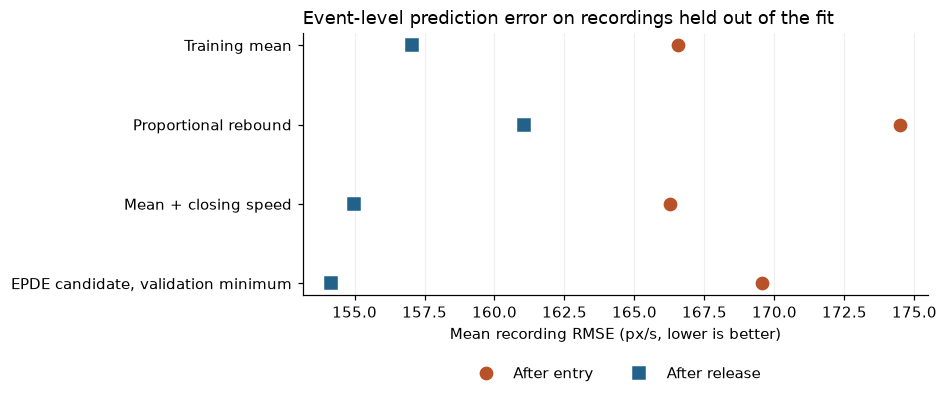

In [7]:
scores = pd.read_csv(rebound / "scores.csv")
local = scores.query("scope == 'loose' and width == 2 and offset == 0")
names = {"constant": "Training mean", "restitution": "Proportional rebound",
         "affine": "Mean + closing speed", "epde": "EPDE candidate, validation minimum"}
event_scores = (local[local.model.isin(names)].groupby(["target", "model"])
                .agg(events=("events", "sum"), rmse=("rmse", "mean"), r2=("r2", "mean")))
assert local.query("model == 'epde' and target == 'release'").terms.nunique() == 1
display(event_scores.rename(index=names, level="model").round(3))

fig, ax = plt.subplots(figsize=(8.5, 3.5), layout="constrained")
for target, marker, color, label in [("entry", "o", orange, "After entry"),
                                      ("release", "s", blue, "After release")]:
    block = event_scores.loc[target].reindex(names)
    ax.plot(block.rmse, list(names.values()), marker=marker, lw=0, ms=8, color=color, label=label)
ax.set(title="Event-level prediction error on recordings held out of the fit",
       xlabel="Mean recording RMSE (px/s, lower is better)")
ax.invert_yaxis()
ax.grid(axis="x", alpha=.2)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2)
plt.show()

The archived study separately compared eligible EPDE candidates by validation RMSE. The same four-term structure attained the minimum in all five release folds. Averaged over recordings, this reporting rule gave 154.2 px/s test RMSE over 907 releases, compared with 157.1 px/s for the training mean. On 1,888 entries the corresponding errors were 169.6 and 166.5 px/s. The entry and release cohorts have different eligibility. In this larger cohort, nearby third robots were allowed outside 1.03 diameters. Requiring continuous isolation out to 253 px leaves only 43 nominal 40 ms releases, all in one recording. These measurements support a recurring equation structure with modest predictive value. [Timing and isolation results](results/collision_transfer/preprocessed/restitution_epde/report.md)

## 3. How a neighbor changes one robot’s velocity

Forward EPDE fitted the vector contribution of nearby robots to the next 0.4 s of motion. Add these contributions to the robot’s own propulsion, its previous velocity and its wall response. The historical report used validation error to identify a structure to refit on the pooled data. Its equation per neighbor is approximately:

```text
neighbor_velocity = 0.111 * approach + 0.038 * drive + 0.236 * drive_in
                  + 10.84 * front + 4.06 * neighbor_front + 263.56 * overlap
```

Here `n` points from the neighbor to the focal robot. Each predictor above is a vector. `approach` is positive closing speed times `n`. `drive` is the neighbor’s propulsion vector, and `drive_in` is its positive projection toward the focal robot, times `n`. The two `front` terms weight `n` by each robot’s signed heading toward the other. `overlap` is the name used for `n * max(253 - center_distance, 0) / 230`. It starts contributing within the 253 px neighborhood, including when the physical rims still have a gap. The 230 px denominator is the original feature scale, while the calibrated physical diameter is 219.55 px.

The left panel evaluates just the distance-dependent term. The right panel scores the entire fitted velocity vector on held-out recordings. The displayed coefficients come from a pooled fit. Each test score evaluates that study procedure with the test recording held out. [Neighbor term definitions](collision/physics.py) · [Pooled equation and validation](results/collision_transfer/report.md)

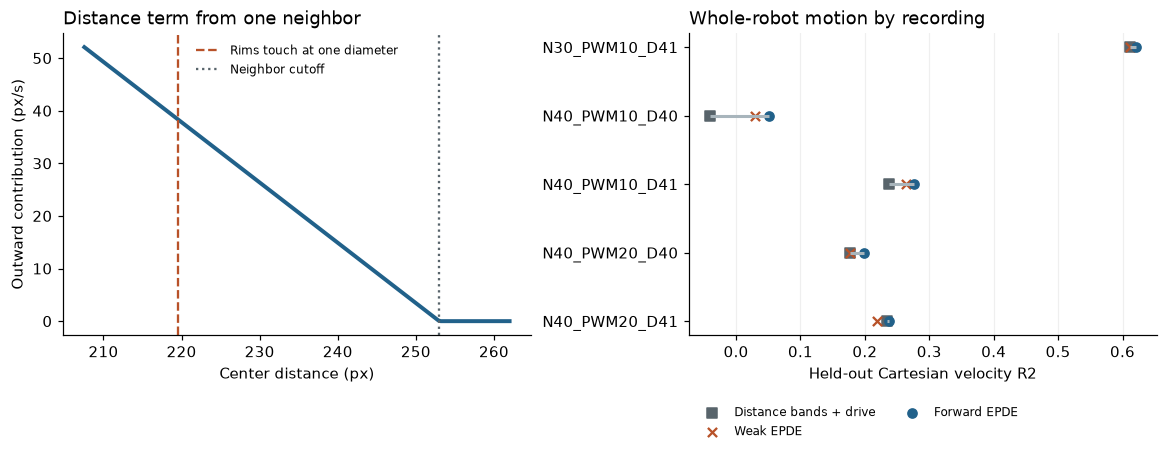

At one diameter: 38.3 px/s from the distance term alone.
Forward EPDE gain over distance bands + drive: +0.0042 to +0.0908 R2.


In [8]:
neighbor = read_json(collision / "pooled_law.json")["coefficients"]
drift_scores = pd.read_csv(collision / "drift_scores.csv")
drift = drift_scores.pivot(index="recording", columns="method", values="r2")
distance = np.linspace(diameter - 12, cutoff + 9, 180)
outward = neighbor["overlap"] * np.maximum(cutoff - distance, 0) / 230

fig, (ax, comparison) = plt.subplots(1, 2, figsize=(10.5, 4), layout="constrained")
ax.plot(distance, outward, color=blue, lw=2.6)
ax.axvline(diameter, color=orange, ls="--", label="Rims touch at one diameter")
ax.axvline(cutoff, color=gray, ls=":", label="Neighbor cutoff")
ax.set(xlabel="Center distance (px)", ylabel="Outward contribution (px/s)",
       title="Distance term from one neighbor")
ax.legend(fontsize=8)

y = np.arange(len(drift))
comparison.hlines(y, drift.banded_drive, drift.strong, color="#A8B5BC", lw=2)
for model, color, marker, label in [("banded_drive", gray, "s", "Distance bands + drive"),
                                    ("weak", orange, "x", "Weak EPDE"),
                                    ("strong", blue, "o", "Forward EPDE")]:
    comparison.scatter(drift[model], y, color=color, marker=marker, label=label)
comparison.set(yticks=y, yticklabels=drift.index, xlabel="Held-out Cartesian velocity R2",
               title="Whole-robot motion by recording")
comparison.invert_yaxis()
comparison.grid(axis="x", alpha=.2)
comparison.legend(loc="upper left", bbox_to_anchor=(0, -0.2), fontsize=8, ncol=2)
plt.show()
at_contact = neighbor["overlap"] * (cutoff - diameter) / 230
gain = drift.strong - drift.banded_drive
print(f"At one diameter: {at_contact:.1f} px/s from the distance term alone.")
print(f"Forward EPDE gain over distance bands + drive: {gain.min():+.4f} to {gain.max():+.4f} R2.")

## 4. How much the pair’s gap can close

A separate search started from a richer vector model. Call its predicted relative normal velocity `u0`, and let `g` be the nonnegative clearance between the robots’ edges from the corrected positions. The geometric rule can use a free-motion estimate, `u_free`. The fitted correction uses the expanded vector model’s `u0`.

```text
geometric_limit = max(u_free, -g / 0.4)
excess_closing  = max(0, -g / 0.4 - u0)
predicted_u     = 4.844 + 0.6925 * u0 + 1.0135 * excess_closing
```

With an 8 px gap, closing at 20 px/s uses up the gap in 0.4 s. The correction turns on for predictions more negative than −20 px/s. The left panel gives both formulas the same input velocity to show their different responses. Its coefficient near one measures how much excess closing speed gets added back over the forecast. The previous vector model here is the expanded, preprocessed model. The raw-track six-term model in section 3 was a separate fit. [Baseline model](results/collision_transfer/preprocessed/search/report.md) · [Pair-correction study](results/collision_transfer/preprocessed/pair_normal/report.md)

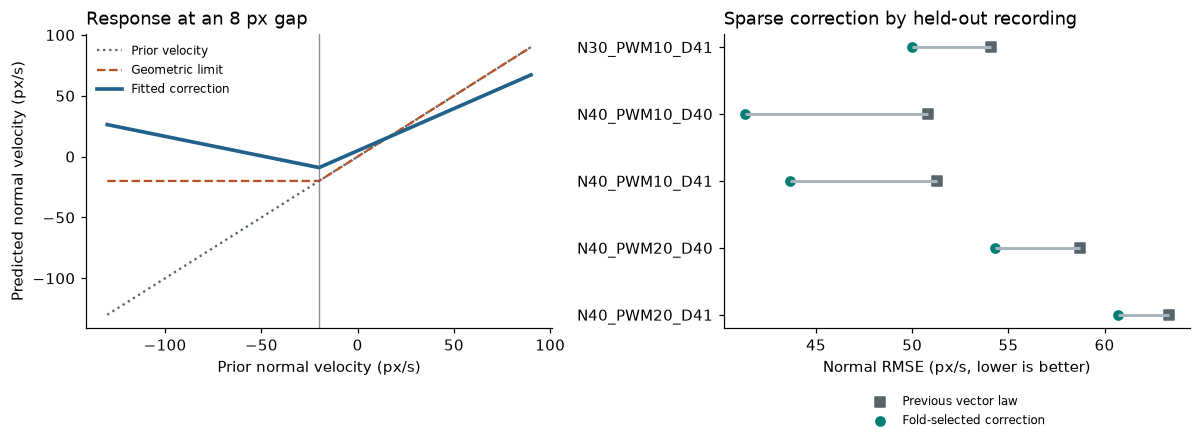

174,120 pair observations.


,Mean normal R2,Mean normal RMSE (px/s)
model,,
Previous vector model,0.103,55.646
Three-term pair correction,0.242,51.706
"Fold-selected sparse, joint velocities",0.290,49.996
"Shared sparse, joint velocities (exploratory)",0.294,49.852
"Boosted reference, joint velocities",0.320,48.966


In [9]:
compact = read_json(normal / "correction/common_law.json")["compact"]

def compact_velocity(u0, gap):
    excess = np.maximum(0, -gap / dt - u0)
    # The archived coefficients predict a residual added to u0.
    return compact["bias"] + (1 + compact["prior"]) * u0 + compact["capCorrection"] * excess

u0 = np.linspace(-130, 90, 300)
gap = 8.0
fig, (ax, fold_ax) = plt.subplots(1, 2, figsize=(10.8, 3.9), layout="constrained")
ax.plot(u0, u0, ":", color=gray, label="Prior velocity")
ax.plot(u0, np.maximum(u0, -gap / dt), "--", color=orange, label="Geometric limit")
ax.plot(u0, compact_velocity(u0, gap), color=blue, lw=2.4, label="Fitted correction")
ax.axvline(-gap / dt, color=gray, lw=.9, alpha=.7)
ax.set(title="Response at an 8 px gap", xlabel="Prior normal velocity (px/s)",
       ylabel="Predicted normal velocity (px/s)")
ax.legend(fontsize=8)

vector = pd.read_csv(normal / "vector_scores.csv")
wide = vector.pivot(index="held", columns="model", values="rmse")
y = np.arange(len(wide))
fold_ax.hlines(y, wide.residual_sparse, wide.previous, color="#A8B5BC", lw=2)
fold_ax.scatter(wide.previous, y, color=gray, marker="s", label="Previous vector law")
fold_ax.scatter(wide.residual_sparse, y, color=green, label="Fold-selected correction")
fold_ax.set(yticks=y, yticklabels=wide.index, xlabel="Normal RMSE (px/s, lower is better)",
            title="Sparse correction by held-out recording")
fold_ax.invert_yaxis()
fold_ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(.5, -.19))
plt.show()

models = {"previous": "Previous vector model", "residual_compact": "Three-term pair correction",
          "coherent_residual_sparse": "Fold-selected sparse, joint velocities",
          "coherent_residual_shared": "Shared sparse, joint velocities (exploratory)",
          "coherent_residual_boosted": "Boosted reference, joint velocities"}
comparison = pd.read_csv(normal / "comparison.csv").set_index("model").loc[list(models)]
print(f"{vector.loc[vector.model.eq('previous'), 'pairs'].sum():,} pair observations.")
display(comparison[["mean_r2", "normal_rmse"]].rename(index=models, columns={
    "mean_r2": "Mean normal R2", "normal_rmse": "Mean normal RMSE (px/s)"}).round(3))

The compact correction raised mean normal R2 from **0.103 to 0.242**. The archived sparse-model summary applied a validation criterion to EPDE and beam-search proposals separately within each training fold. Assigning one velocity to each robot across simultaneous encounters raised its mean normal R2 to **0.290**, with RMSE falling from **55.65 to 50.00 px/s** relative to the previous vector law. The shared sparse structure was assembled using proposals from all five training folds and is exploratory. The boosted row provides a nonlinear benchmark. [Term dictionary](results/collision_transfer/preprocessed/pair_normal/term_dictionary.csv) · [Model comparison](results/collision_transfer/preprocessed/pair_normal/comparison.csv)

In [10]:
# The pooled, shared correction adds sum(coefficient * term) to u0.
# Keep the term definitions next to the fitted values for interpreting this longer equation.
shared = pd.Series(read_json(normal / "correction/common_law.json")["shared"], name="Coefficient")
dictionary = pd.read_csv(normal / "term_dictionary.csv").set_index("term")
terms_table = shared.to_frame().join(dictionary, how="left")
assert terms_table.definition.notna().all()
with pd.option_context("display.max_colwidth", 100):
    display(terms_table.round(4))

,Coefficient,definition
near2,0.0331,(D/T) Near²
limit2,0.0481,"Maximum of u and −g/T, using the past 2 frames"
turnLimit20,0.0485,"Maximum of turn and −g/T minus its tangential curvature term, using the past 20 frames"
spinMagnitude,3.2794,Mean absolute ten-frame angular speed
gapSpeed*Crowded,-0.1799,"Product of gapSpeed, Crowded"
priorClosing,0.5396,Positive part of −prior
freeCapCorrection,0.2124,Positive part of −g/T − freeNormal minus the free tangential curvature term
individualIn,-0.2850,Sum of the positive inward projections of the individual calibrated propulsion vectors
prior*Near,-0.4358,"Product of prior, Near"
prior*Crowded,-0.1063,"Product of prior, Crowded"


## 5. Normal approach and sideways sliding in three population sweeps

The second dataset uses 50 Hz tracks and a physical robot diameter of 48.7 mm. Its model inputs use body diameters for length and seconds for time. For each close pair, project its next 0.4 s of relative motion onto the normal and tangent at the starting frame. A calibrated free-motion prediction, recent motion, clearance, spin and third-neighbor geometry supply candidate terms. The model predicts relative velocity in body diameters per second. R2 is dimensionless.

Each plot compares predictions on one entire held-out experiment. The plot reproduces the archived analyst comparison using the minimum-validation-RMSE member from each native front. The full live fronts appear below. The free-motion and geometric rules serve as baselines. [Feature construction](collision/new_pair_interactions.py) · [Physical calibration](collision/new_pair_physical.py) · [Model selection](collision/new_pair_models.py)

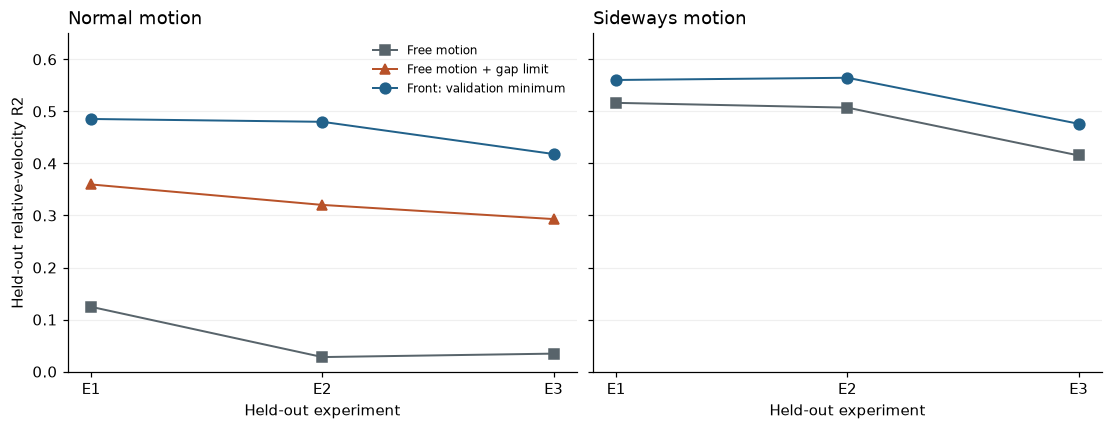

OUTWARD, experiment 2 held out (R2 = 0.480)
  -0.03793  constant
  +0.05545  closing
  +0.71616  free_hinge
  +0.73274  free_normal
  +0.21278  proximity
  +0.01380  spin_magnitude
  +0.11758  third_normal

TANGENT, experiment 2 held out (R2 = 0.565)
  -0.00007  constant
  -0.06967  crowd_side
  +0.86228  free_side
  +0.01653  prior_side
  +0.07253  same_slide
  +0.05347  side
  +0.18558  third_tangent



In [11]:
sweep_scores = pd.read_csv(sweeps / "with_drive/heldout.csv").query("group == 'all'")
sweep_models = {"free motion only": ("Free motion", gray, "s"),
                "free motion clipped to clearance": ("Free motion + gap limit", orange, "^"),
                "native EPDE front": ("Front: validation minimum", blue, "o")}
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True, layout="constrained")
for ax, target, title in zip(axes, ["outward", "tangent"], ["Normal motion", "Sideways motion"]):
    block = sweep_scores.loc[sweep_scores.target.eq(target)]
    for key, (label, color, marker) in sweep_models.items():
        rows = block.loc[block.model.eq(key)].sort_values("held")
        if len(rows):
            ax.plot(rows.held.str.replace("Experiment_", "E", regex=False), rows.r2,
                    color=color, marker=marker, lw=1.3, ms=7, label=label)
    ax.set(title=title, xlabel="Held-out experiment", ylim=(0, .65))
    ax.grid(axis="y", alpha=.2)
axes[0].set_ylabel("Held-out relative-velocity R2")
axes[0].legend(fontsize=8)
plt.show()

# Two members reported under the archived validation criterion with experiment 2 held out.
example = sweep_scores.query("held == 'Experiment_2' and model == 'native EPDE front'")
for row in example.itertuples():
    print(f"{row.target.upper()}, experiment 2 held out (R2 = {row.r2:.3f})")
    for term, b in json.loads(row.coef).items():
        print(f"  {b:+.5f}  {term}")
    print()

### What the interaction terms measure

For the **normal** equation, imagine looking down on two approaching robots and drawing a line between their centers. Each term predicts how much the pair moves along that line. Positive normal speed means the centers move apart. The prediction combines these measurements over the next 0.4 s.

| Term in the Experiment 2 normal equation | Physical meaning |
|---|---|
| `constant` | Small signed offset added to every forecast. |
| `free_normal` | How fast the centers would approach or separate if each robot followed its own calibrated motion. Two robots moving together at the same velocity give zero relative motion. |
| `closing` | How quickly the pair was actually approaching in its recent tracking history. It is zero if the pair was already opening. |
| `free_hinge` | The part of the free-motion approach that would use more than the available edge gap. A 0.10-diameter gap allows 0.25 diameters/s of closing over 0.4 s. A free forecast of 0.60 diameters/s inward gives `free_hinge = 0.35`. |
| `proximity` | Closeness of the two centers. It equals zero at 1.30 diameters and one when the rims touch at one diameter. |
| `spin_magnitude` | Strength of the pair’s net spin, weighted by proximity. Nearby equal spins in the same direction add. Equal opposite spins cancel. |
| `third_normal` | Where other robots sit relative to the pair. Each nearby center contributes a vector pointing away from it. Taking the difference across the pair captures whether that geometry points toward opening or closing. |

Across the three experiments, the archived validation-minimum equations reached held-out R2 of **0.42–0.49** for normal motion and **0.48–0.56** for sideways motion. For sideways motion, the weight on the free-motion prediction ranged from **0.845 to 0.884**. The smaller spin and history terms varied between fits. [All selected coefficients and test scores](results/pair_interactions_sweeps/physical/with_drive/heldout.csv)

<details>
<summary>Terms that can appear in other Pareto equations</summary>

| Candidate | How to read it |
|---|---|
| `incoming`, `prior` | Signed normal velocity in the recent and earlier windows. In this population-sweep code a negative value means the robots were approaching. |
| `gap`, `hinge` | Edge-to-edge clearance, floored at zero, and the amount by which the **recent measured** closing speed would exhaust that clearance over 0.4 s. The corresponding `free_hinge` uses the **free-motion forecast**. |
| `abs_side`, `bend` | Magnitude of recent sideways speed and its geometric curvature term, `side**2 * 0.4 / (2*r)`. Two robots passing sideways can increase their center distance even when their initial normal speed is zero. |
| `crowd`, `same_near` | The nearby-third-robot indicator, and closeness multiplied by the same-spin indicator, respectively. |
| `slide_near`, `side_closing` | Recent signed sideways speed multiplied by closeness or by positive closing speed. These terms let sliding depend on how close or how fast-approaching the pair is. |
| `spin_slide` | Closeness multiplied by the mean signed spin of the pair. Reversing both spin directions reverses its sign. |
    
</details>

### The sideways equation in mathematical notation

Imagine looking straight down on the robots. If they drive directly toward one another, their relative sideways speed is zero. If they pass shoulder to shoulder, their relative sideways speed can be large. The sign records which way they pass along the sideways axis. If they move together at the same velocity, their relative speed is zero even while both robots are moving.

The displayed coefficients are the archived fit with **Experiment 2 held out**. At frame $k$, let $\mathbf x_a[k]$ be robot $a$’s center in body diameters, $\mathbf r[k]=\mathbf x_j[k]-\mathbf x_i[k]$, $\mathbf n=\mathbf r[k]/\lVert\mathbf r[k]\rVert$, and $\boldsymbol\tau=(-n_y,n_x)$. Freeze $\boldsymbol\tau$ at frame $k$. The target $s^+=\boldsymbol\tau\cdot(\mathbf r[k+20]-\mathbf r[k])/0.4$ is signed sideways speed over the next 0.4 s.

$$
\widehat{s^+}=-0.00007+0.86228\,f+0.01653\,p
       +\bigl(0.05347-0.06967\,C+0.07253\,zS\bigr)s+0.18558\,h .
$$

In plain text:

~~~text
side_next = -0.00007 + 0.86228*f + 0.01653*p
          + (0.05347 - 0.06967*C + 0.07253*z*S)*s + 0.18558*h
~~~

| EPDE term | Mathematical equivalent | How to read its contribution in this fit |
|---|---|---|
| <code>constant</code> | $1$ | Adds −0.00007 body diameters/s in every case. The fitted offset is very small. |
| <code>free_side</code> | $f=\boldsymbol\tau\cdot(\widehat{\mathbf v}^{\,free}_j-\widehat{\mathbf v}^{\,free}_i)$ | Given each robot’s own heading and motion history, how fast would they pass sideways? A free prediction of +1 diameter/s contributes +0.86228 diameters/s to the pair forecast. |
| <code>side</code> | $s=\boldsymbol\tau\cdot(\mathbf r[k-1]-\mathbf r[k-11])/0.20$ | How fast they actually slid sideways 220–20 ms before the forecast. The positive coefficient carries a small part of that recent motion forward. |
| <code>prior_side</code> | $p=\boldsymbol\tau\cdot(\mathbf r[k-12]-\mathbf r[k-22])/0.20$ | The same measurement one window earlier, 440–240 ms before the forecast. Its smaller positive weight gives the older motion less influence. |
| <code>crowd_side</code> | $Cs$ | $C=1$ if a third center lies within 1.15 diameters of either member, otherwise $C=0$. When the pair is crowded, this term subtracts 0.06967 times its recent signed slide. A negative slide therefore gives a positive correction. |
| <code>same_slide</code> | $zSs$ | $S=1$ if both robots spin the same way, otherwise $S=0$. The closeness weight is $z=\max(1.30-\lVert\mathbf r[k]\rVert,0)/0.30$. For a close, co-rotating pair this adds a contribution in the direction it was already sliding. |
| <code>third_tangent</code> | $h=\boldsymbol\tau\cdot(\mathbf A_j-\mathbf A_i)/0.30$ | Where the other neighbors are on either side of the pair. Similar sideways contributions to both robots cancel. A neighbor closer to one member can give a signed sideways correction even when the pair’s recent slide was zero. |

Spin direction uses the sign of each robot’s mean angular velocity from its unwrapped heading, $\omega_a=(\phi_a[k-1]-\phi_a[k-21])/0.4$.

For $a=i,j$, write $d_{am}=\lVert\mathbf x_a[k]-\mathbf x_m[k]\rVert$. The study uses
$$
\mathbf A_a=\sum_{\substack{m\notin\{i,j\}\\d_{am}>0}}
       \max(1.30-d_{am},0)\,
       \frac{\mathbf x_a[k]-\mathbf x_m[k]}{d_{am}} .
$$

A third robot between 1.15 and 1.30 diameters can contribute to $h$ while $C$ stays zero. A positive $h$ raises the predicted sideways velocity. The effect of crowding also depends on the direction of motion already present: when $C=1$ and $S=0$, the coefficient multiplying $s$ changes from +0.05347 to −0.01620. Velocities use body diameters/s. $C$, $S$, $z$ and $h$ are dimensionless. [Pair geometry and timing](collision/new_pair_interactions.py) · [Free-motion calibration](collision/new_pair_free_motion.py)

### Run the two pair searches

Set the held-out experiment, seed, population and generation count in the next cell and rerun this section. The defaults match the physical-scale population-sweep study. EPDE proposes structures on a balanced sample of training rows after centering each predictor and response. The full training prefixes supply the coefficient refits with one intercept and equal total weight per experiment. Validation uses the final quarters of those same experiments. The held-out experiment supplies the final score.

The training objectives are centered WAPE (sum of absolute errors divided by the sum of absolute centered targets) and dyadic coefficient instability. Smaller values are preferable on both axes. The objective plot and the subsequent tables use the equations returned by the new in-kernel searches. [Original sweep fitting procedure](collision/new_pair_models.py)

In [12]:
import new_pair_models as pair_models

pair_holdout = "Experiment_2"
search_seed = 923701
population_size = 16
generations = 12
maximum_terms = 6
screen_per_experiment = 640

# Select the same physically calibrated data and holdout-specific free-motion predictors as the study.
with patch.multiple(pair_models, PHYSICAL=True, USE_DRIVE=True):
    pair_data = pair_models.inputs(pair_holdout)
pair_train, pair_valid, pair_test = pair_models.split(pair_data, pair_holdout)
pair_screen = pd.concat([
    group.sample(min(screen_per_experiment, len(group)), random_state=542 + i)
         .sort_values(["N", "frame", "id_i", "id_j"])
    for i, (_, group) in enumerate(pair_train.groupby("experiment"))
])
predictors = {
    "outward": [*pair_models.HISTORY["outward"], "free_normal", *pair_models.GAP["outward"],
                "free_hinge", *pair_models.THIRD["outward"], *pair_models.SPIN["outward"]],
    "tangent": [*pair_models.HISTORY["tangent"], "free_side", *pair_models.GAP["tangent"],
                *pair_models.THIRD["tangent"], *pair_models.SPIN["tangent"]],
}
print(f"{pair_holdout} held out. Training: {len(pair_train):,}. Validation: {len(pair_valid):,}. "
      f"Test: {len(pair_test):,}. Balanced search sample: {len(pair_screen):,}.")

Experiment_2 held out. Training: 78,205. Validation: 26,466. Test: 54,820. Balanced search sample: 1,280.


#### Check the symbols against a measured pair

The next cell reconstructs all seven columns from one tracked encounter and the fitted free-motion coefficients. It chooses an example with a nearby third robot, two spins of the same sign, and a measurable transverse component so both interaction products are active. The comparison uses the selected holdout’s calibration.

In [13]:
import zipfile
from new_pair_interactions import read_stage

case = pair_test.loc[pair_test["same"] & pair_test["crowd"].eq(1)
                     & pair_test.side.abs().gt(0.05) & pair_test.third_tangent.abs().gt(0.05)].iloc[0]
size, k = int(case.N), int(case.frame)
with zipfile.ZipFile(robot / f"{pair_holdout}.zip") as files:
    member, = [name for name in files.namelist() if f"/data_N={size}_" in name]
    _, ids, pos, phi, _ = read_stage(files, member, size)

scale = pd.read_csv(sweeps / "scale.csv").set_index(["experiment", "N"])
diam = scale.loc[(pair_holdout, size), "diameter_archive_units"]
ref = read_json(sweeps.parent / "inputs.json")[pair_holdout]["reference_spacing"]
i, j = (ids.tolist().index(int(value)) for value in (case.id_i, case.id_j))
relative = (pos[:, j] - pos[:, i]) / diam
n = relative[k] / abs(relative[k])
# For complex x+iy positions, imag(v * conj(n)) is the dot product with (-n_y, n_x).
def sideways(v):
    return (v * n.conjugate()).imag

s = sideways(relative[k-1] - relative[k-11]) / 0.20
p = sideways(relative[k-12] - relative[k-22]) / 0.20
z = max(1.30 - abs(relative[k]), 0) / 0.30
omega = (phi[k-1] - phi[k-21]) / 0.40
same_sign = float(omega[i] * omega[j] > 0)

others = np.ones(size, dtype=bool)
others[[i, j]] = False
def neighbor_geometry(a):
    offsets = (pos[k, a] - pos[k, others]) / diam
    dist = abs(offsets)
    direction = np.divide(offsets, dist, out=np.zeros_like(offsets), where=dist > 0)
    return np.sum(np.maximum(1.30 - dist, 0) * direction), np.min(dist, initial=np.inf)

A_i, nearest_i = neighbor_geometry(i)
A_j, nearest_j = neighbor_geometry(j)
crowded = float(min(nearest_i, nearest_j) < 1.15)
h = sideways(A_j - A_i) / 0.30

cal = pd.read_csv(sweeps.parent / "free_motion_calibration.csv").set_index(["held", "id"])
def free_velocity(a):
    # The calibration used reference-spacing units. Convert its output to diameters/s.
    pairs = json.loads(cal.loc[(pair_holdout, ids[a]), "coefficients"])
    beta = np.array([complex(real, imag) for real, imag in pairs])
    v = (pos[k-1, a] - pos[k-11, a]) / (0.20 * ref)
    old_v = (pos[k-12, a] - pos[k-22, a]) / (0.20 * ref)
    return (beta @ [1, np.cos(phi[k, a]), np.sin(phi[k, a]), v, old_v]) * ref / diam

f = sideways(free_velocity(j) - free_velocity(i))
values = pd.Series({"constant": 1., "crowd_side": crowded*s, "free_side": f,
                    "prior_side": p, "same_slide": z*same_sign*s, "side": s, "third_tangent": h})
saved = pd.Series({name: 1. if name == "constant" else case[name] for name in values.index})
np.testing.assert_allclose(values, saved, rtol=2e-7, atol=2e-8)
print(f"{pair_holdout}, N={size}, frame {k}, robots {ids[i]} and {ids[j]}")
display(pd.DataFrame({"From positions and calibration": values, "Archived input": saved}).round(5))

Experiment_2, N=5, frame 1322, robots 29 and 46


,From positions and calibration,Archived input
constant,1.00000,1.00000
crowd_side,-0.86009,-0.86009
free_side,-0.68792,-0.68792
prior_side,0.11913,0.11913
same_slide,-0.69342,-0.69342
side,-0.86009,-0.86009
third_tangent,-1.23329,-1.23329


#### How the seven terms add up in one encounter

The left panel rotates the measured positions so the line from the first robot to the second runs horizontally. Up is the positive sideways direction. The right panel multiplies each measured input by its published Experiment 2 coefficient. The bars all have the same units, so their sum is the predicted sideways speed.

In the default example, robots 29 and 46 were already sliding in the negative direction. Their individual free-motion forecasts and the locations of other robots also point that way. The crowd correction partly offsets the slide. Several inputs describe related aspects of the same encounter, so these numbers describe the fitted prediction. A comparison involving a change to one coefficient or input holds the others fixed.

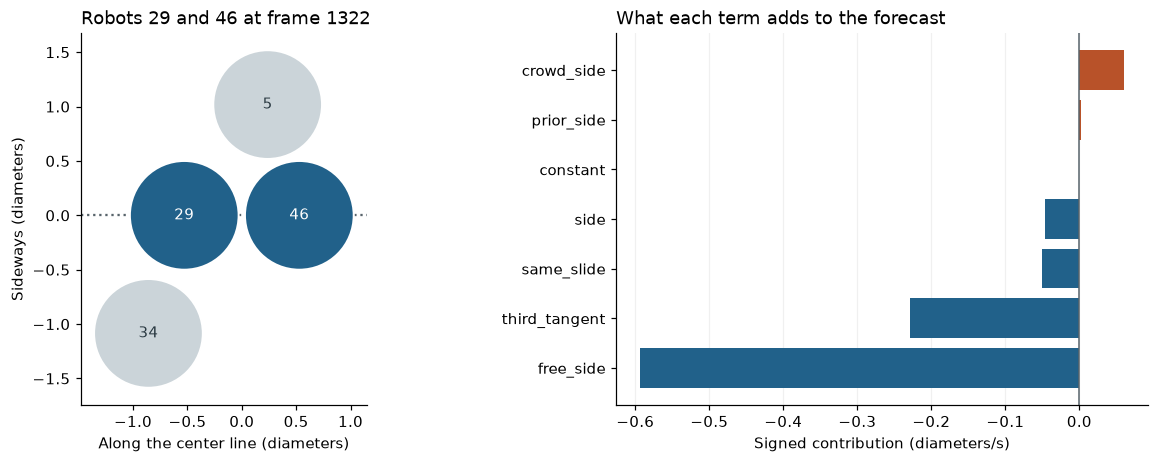

Sum of seven terms: -0.857 diameters/s. Measured next 0.4 s: -0.775 diameters/s.


,Measured input,Fitted coefficient,Contribution (diameters/s)
constant,1.00000,-0.00007,-0.00007
crowd_side,-0.86009,-0.06967,0.05992
free_side,-0.68792,0.86228,-0.59318
prior_side,0.11913,0.01653,0.00197
same_slide,-0.69342,0.07253,-0.05029
side,-0.86009,0.05347,-0.04599
third_tangent,-1.23329,0.18558,-0.22887


In [14]:
from matplotlib.patches import Circle

# Keep the displayed seven-term equation fixed when exploring another pair or holdout.
tangent_row = example.loc[example.target.eq("tangent")].iloc[0]
coefficient = pd.Series(json.loads(tangent_row.coef)).reindex(values.index)
assert coefficient.notna().all()
effect = coefficient * values
total = effect.sum()
# Check the expanded sum against the grouped equation in section 5.
slide_weight = (coefficient["side"] + coefficient["crowd_side"] * crowded
                + coefficient["same_slide"] * z * same_sign)
grouped = (coefficient["constant"] + coefficient["free_side"] * f
           + coefficient["prior_side"] * p + slide_weight * s + coefficient["third_tangent"] * h)
np.testing.assert_allclose(total, grouped)

fig, (pose_ax, effect_ax) = plt.subplots(1, 2, figsize=(10.9, 4.1), layout="constrained")
midpoint = (pos[k, i] + pos[k, j]) / 2
local_pos = (pos[k] - midpoint) * n.conjugate() / diam
dist_to_pair = np.minimum(abs(local_pos - local_pos[i]), abs(local_pos - local_pos[j]))
for a in np.flatnonzero(dist_to_pair < 1.30):
    xy = local_pos[a]
    pair_member = a in (i, j)
    pose_ax.add_patch(Circle((xy.real, xy.imag), .5, facecolor=blue if pair_member else "#CBD4D9",
                             edgecolor="white", lw=1.3, zorder=2))
    pose_ax.text(xy.real, xy.imag, str(ids[a]), ha="center", va="center", zorder=3,
                 color="white" if pair_member else "#283740")
pose_ax.axhline(0, ls=":", color=gray, zorder=1)
pose_ax.autoscale_view()
pose_ax.set_aspect("equal")
pose_ax.set(title=f"Robots {ids[i]} and {ids[j]} at frame {k}", xlabel="Along the center line (diameters)",
            ylabel="Sideways (diameters)")

ordered = effect.sort_values()
effect_ax.barh(ordered.index, ordered, color=[blue if v < 0 else orange for v in ordered])
effect_ax.axvline(0, color=gray, lw=1)
effect_ax.set(title="What each term adds to the forecast", xlabel="Signed contribution (diameters/s)")
effect_ax.grid(axis="x", alpha=.18)
plt.show()
print(f"Sum of seven terms: {total:+.3f} diameters/s. Measured next 0.4 s: {case.tangent:+.3f} diameters/s.")
display(pd.DataFrame({"Measured input": values, "Fitted coefficient": coefficient,
                      "Contribution (diameters/s)": effect}).round(5))

#### Interpret every equation on the Pareto fronts

Each dot represents an evaluated equation. Moving left lowers the total absolute training error relative to the magnitude of the centered training observations (WAPE). Moving down indicates coefficients that vary less when EPDE refits on subdivisions of the training sample. A point is dominated when another does at least as well on both objectives and strictly better on at least one. The circles mark the front returned by EPDE. The dashed line shows the nondominated envelope over the larger set of structures captured during the run.

Read each circled equation across the tables using its row number. For each row the notebook reports both search objectives, refits the coefficients on the full training prefixes, and evaluates the same validation and held-out observations. RMSE gives greater weight to large misses and is measured in body diameters/s here. Held-out R2 equals 1 for perfect predictions and 0 for the squared error of guessing the held-out mean.

The final column compares each equation with a simpler member of the same front when one is nested inside it. It uses the largest proper subset of terms and breaks ties by the lower training WAPE. A negative change in validation RMSE means the extra terms improved predictive accuracy on the validation data. A positive change in instability means the coefficients varied more. All coefficients are refitted for both structures. These differences describe model behavior across recordings. [Archived equations and per-member scores](results/pair_interactions_sweeps/physical/with_drive/native_fronts.csv)

In [15]:
def fit_pair_front(target):
    names = predictors[target]
    frame = pair_screen[names]
    centered = frame - frame.mean()
    x = {name: centered[name].to_numpy() for name in names}
    y = pair_screen[target].to_numpy()
    with redirect_stdout(StringIO()):
        return run_epde(y - y.mean(), x, seed=search_seed, population=population_size,
                        generations=generations, max_terms=maximum_terms)

pair_runs = {}
for target in ("outward", "tangent"):
    pair_runs[target] = fit_pair_front(target)
    result = pair_runs[target]
    print(f"{target}: {len(result['evaluated'])} evaluated structures, "
          f"{len(result['front'])} equations on the returned front.")

outward: 782 evaluated structures, 11 equations on the returned front.


tangent: 465 evaluated structures, 6 equations on the returned front.


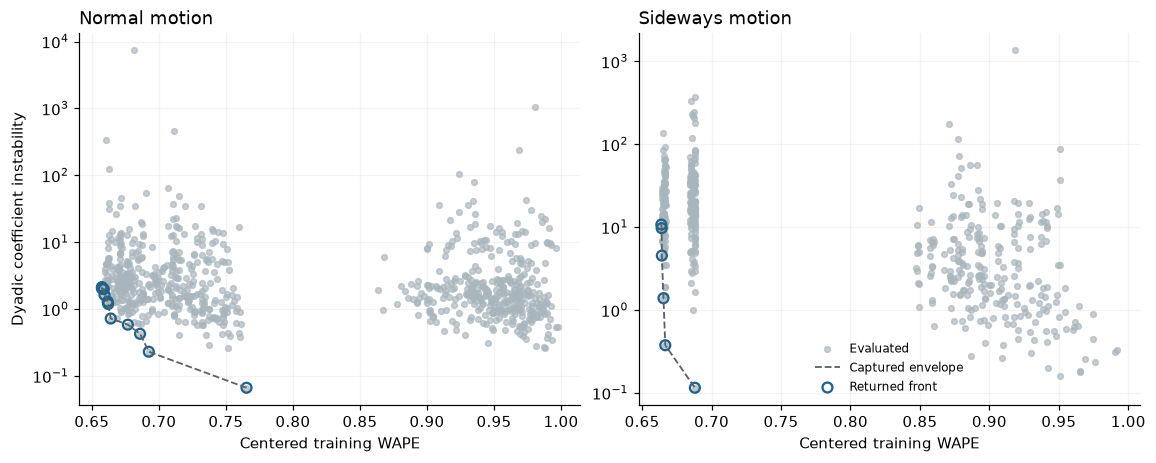

OUTWARD | every returned equation, ordered by training WAPE. RMSE in diameters/s.


,Terms,size,WAPE,dyad,validation RMSE,held-out RMSE,held-out R2
Row,,,,,,,
0,closing + free_hinge + free_normal + proximity + spin_magnitude + third_normal,6,0.65749,2.13603,0.27807,0.27132,0.48000
1,free_hinge + free_normal + incoming + proximity + spin_magnitude + third_normal,6,0.65759,2.02496,0.27831,0.27170,0.47856
2,free_hinge + free_normal + proximity + same_near + spin_magnitude + third_normal,6,0.65893,1.98984,0.27821,0.27181,0.47814
3,free_hinge + free_normal + proximity + spin_magnitude + third_normal,5,0.65943,1.63446,0.27862,0.27257,0.47520
4,closing + free_hinge + free_normal + proximity + third_normal,5,0.66181,1.29683,0.27837,0.27162,0.47887
5,free_hinge + free_normal + incoming + proximity + third_normal,5,0.66221,1.19342,0.27863,0.27201,0.47737
6,free_hinge + free_normal + proximity + third_normal,4,0.66412,0.72392,0.27897,0.27293,0.47383
7,free_hinge + free_normal + proximity,3,0.67688,0.58564,0.28698,0.28024,0.44525
8,free_hinge + free_normal + third_normal,3,0.68599,0.42761,0.28582,0.27971,0.44735


TANGENT | every returned equation, ordered by training WAPE. RMSE in diameters/s.


,Terms,size,WAPE,dyad,validation RMSE,held-out RMSE,held-out R2
Row,,,,,,,
0,crowd_side + free_side + prior_side + same_slide + side + third_tangent,6,0.66382,10.73306,0.34180,0.33046,0.56462
1,crowd_side + free_side + prior_side + side + slide_near + third_tangent,6,0.66406,9.70663,0.34182,0.33018,0.56536
2,crowd_side + free_side + prior_side + same_slide + third_tangent,5,0.66422,4.53288,0.34212,0.33041,0.56476
3,free_side + prior_side + third_tangent,3,0.66535,1.38687,0.34254,0.33014,0.56546
4,free_side + third_tangent,2,0.66668,0.37535,0.34277,0.33031,0.56501
5,free_side,1,0.68798,0.11510,0.35782,0.34547,0.52417


In [16]:
def score_front(target, result):
    rows = []
    y_test = pair_test[target].to_numpy()
    for item in result["front"]:
        names = sorted(item["terms"])
        beta = pair_models.fit(pair_train, target, names)
        errors = [pair_models.metrics(group[target].to_numpy(), pair_models.predict(group, names, beta))["rmse"]
                  for _, group in pair_valid.groupby("experiment")]
        measured = pair_models.metrics(y_test, pair_models.predict(pair_test, names, beta))
        rows.append({"Terms": " + ".join(names), "support": tuple(names), "size": len(names),
                     "WAPE": item["wape"], "dyad": item["dyad"], "validation RMSE": np.mean(errors),
                     "held-out RMSE": measured["rmse"], "held-out R2": measured["r2"],
                     "coefficients": dict(zip(["constant", *names], beta))})
    front = pd.DataFrame(rows).sort_values(["WAPE", "dyad", "Terms"]).reset_index(drop=True).rename_axis("Row")
    assert len(front) == len(result["front"])
    front["Nested comparison"] = nested_comparisons(front)
    return front

pair_fronts = {target: score_front(target, result) for target, result in pair_runs.items()}
def captured_envelope(points):
    ordered = points[["WAPE", "dyad"]].drop_duplicates().sort_values(["WAPE", "dyad"])
    return ordered.loc[ordered.dyad.lt(ordered.dyad.cummin().shift(fill_value=np.inf))]

fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.1), layout="constrained")
for ax, (target, table) in zip(axes, pair_fronts.items()):
    points = pd.DataFrame([{"WAPE": r["wape"], "dyad": r["dyad"]}
                           for r in pair_runs[target]["evaluated"]])
    # Large finite instability penalties can span orders of magnitude. A symmetric
    # log scale preserves exact zeros in the plotted scores.
    visible = points[np.isfinite(points.WAPE) & np.isfinite(points.dyad)]
    ax.scatter(visible.WAPE, visible.dyad, s=14, c="#A8B5BC", alpha=.65, label="Evaluated")
    envelope = captured_envelope(visible)
    ax.plot(envelope.WAPE, envelope.dyad, color=gray, lw=1.2, ls="--", label="Captured envelope")
    ax.scatter(table.WAPE, table.dyad, s=42, facecolor="none", edgecolor=blue,
               linewidth=1.5, label="Returned front")
    ax.set_yscale("symlog", linthresh=0.1)
    ax.set(title="Normal motion" if target == "outward" else "Sideways motion",
           xlabel="Centered training WAPE")
    ax.grid(alpha=.15)
axes[0].set_ylabel("Dyadic coefficient instability")
axes[1].legend(fontsize=8)
plt.show()

for target, table in pair_fronts.items():
    print(f"{target.upper()} | every returned equation, ordered by training WAPE. RMSE in diameters/s.")
    show_rows(table[["Terms", "size", "WAPE", "dyad", "validation RMSE", "held-out RMSE", "held-out R2"]]
              .round(5))

In [17]:
archived_sweep_front = pd.read_csv(sweeps / "with_drive/native_fronts.csv")

def linear_equation(coefficients):
    intercept = coefficients["constant"]
    return (f"{intercept:+.5f}" + "".join(f" {value:+.5f}*{term}"
            for term, value in coefficients.items() if term != "constant"))

# Read every term in a returned equation in the same order as its fitted coefficient.
meaning = {"free_normal": "free closing or opening motion", "free_hinge": "excess closing under free motion",
           "proximity": "closeness of this pair", "third_normal": "other robots along the center line",
           "closing": "recent closing speed", "spin_magnitude": "magnitude of proximity-weighted spin",
           "incoming": "signed recent normal speed", "same_near": "closeness while co-rotating",
           "hinge": "excess closing under recent measured motion", "prior": "earlier normal speed",
           "bend": "curvature from sideways passage", "abs_side": "magnitude of straight-across motion",
           "crowd": "presence of a third robot", "free_side": "free sideways motion",
           "prior_side": "earlier sideways motion", "side": "recent sideways motion",
           "crowd_side": "recent slide when crowded", "same_slide": "close co-rotating slide",
           "third_tangent": "asymmetry of neighbors across the pair", "slide_near": "close-pair slide",
           "spin_slide": "signed spin weighted by closeness", "side_closing": "slide weighted by closing speed"}

for target, table in pair_fronts.items():
    baseline = pair_models.metrics(pair_test[target].to_numpy(),
                                  pair_test["free_normal" if target == "outward" else "free_side"].to_numpy())
    print(f"{target.upper()} | {pair_holdout} | free-motion baseline RMSE {baseline['rmse']:.4f} "
          f"diameters/s, R2 {baseline['r2']:.3f}")
    details = pd.DataFrame(index=table.index)
    details["Refitted equation (diameters/s)"] = table.coefficients.map(linear_equation)
    details["Physical terms"] = table.support.map(lambda s: ", ".join(meaning[t] for t in s))
    details["Nested comparison"] = table["Nested comparison"]
    show_rows(details)
    # Independent verification wherever the present and archived runs share a structure.
    for row in table.to_dict("records"):
        archived = archived_sweep_front.loc[(archived_sweep_front.held == pair_holdout)
                                            & (archived_sweep_front.target == target)
                                            & (archived_sweep_front.terms == row["Terms"])]
        if not archived.empty:
            reference = archived.iloc[0]
            np.testing.assert_allclose([row["validation RMSE"], row["held-out RMSE"], row["held-out R2"]],
                                       [reference.validation_rmse, reference.rmse, reference.r2], atol=1e-8)
            np.testing.assert_allclose(list(row["coefficients"].values()),
                                       json.loads(reference.refit), atol=1e-8)

OUTWARD | Experiment_2 | free-motion baseline RMSE 0.3710 diameters/s, R2 0.028


,Refitted equation (diameters/s),Physical terms,Nested comparison
Row,,,
0,-0.03793 +0.05545*closing +0.71616*free_hinge +0.73274*free_normal +0.21278*proximity +0.01380*spin_magnitude +0.11758*third_normal,"recent closing speed, excess closing under free motion, free closing or opening motion, closeness of this pair, magnitude of proximity-weighted spin, other robots along the center line","vs row 3, add closing. Validation RMSE -0.0006, instability +0.502."
1,-0.02351 +0.73984*free_hinge +0.73737*free_normal -0.03435*incoming +0.20130*proximity +0.01412*spin_magnitude +0.11848*third_normal,"excess closing under free motion, free closing or opening motion, signed recent normal speed, closeness of this pair, magnitude of proximity-weighted spin, other robots along the center line","vs row 3, add incoming. Validation RMSE -0.0003, instability +0.390."
2,-0.02470 +0.74606*free_hinge +0.71733*free_normal +0.20376*proximity -0.09205*same_near +0.04362*spin_magnitude +0.12206*third_normal,"excess closing under free motion, free closing or opening motion, closeness of this pair, closeness while co-rotating, magnitude of proximity-weighted spin, other robots along the center line","vs row 3, add same_near. Validation RMSE -0.0004, instability +0.355."
3,-0.02309 +0.74634*free_hinge +0.71857*free_normal +0.20961*proximity +0.01495*spin_magnitude +0.12279*third_normal,"excess closing under free motion, free closing or opening motion, closeness of this pair, magnitude of proximity-weighted spin, other robots along the center line","vs row 6, add spin_magnitude. Validation RMSE -0.0003, instability +0.911."
4,-0.03801 +0.05717*closing +0.71827*free_hinge +0.73377*free_normal +0.23845*proximity +0.11739*third_normal,"recent closing speed, excess closing under free motion, free closing or opening motion, closeness of this pair, other robots along the center line","vs row 6, add closing. Validation RMSE -0.0006, instability +0.573."
5,-0.02314 +0.74273*free_hinge +0.73865*free_normal -0.03558*incoming +0.22719*proximity +0.11830*third_normal,"excess closing under free motion, free closing or opening motion, signed recent normal speed, closeness of this pair, other robots along the center line","vs row 6, add incoming. Validation RMSE -0.0003, instability +0.469."
6,-0.02268 +0.74964*free_hinge +0.71921*free_normal +0.23737*proximity +0.12276*third_normal,"excess closing under free motion, free closing or opening motion, closeness of this pair, other robots along the center line","vs row 7, add third_normal. Validation RMSE -0.0080, instability +0.138."
7,-0.05594 +0.77056*free_hinge +0.72368*free_normal +0.20929*proximity,"excess closing under free motion, free closing or opening motion, closeness of this pair","vs row 9, add proximity. Validation RMSE -0.0052, instability +0.355."
8,+0.08826 +0.87992*free_hinge +0.73373*free_normal +0.11024*third_normal,"excess closing under free motion, free closing or opening motion, other robots along the center line","vs row 9, add third_normal. Validation RMSE -0.0064, instability +0.197."


TANGENT | Experiment_2 | free-motion baseline RMSE 0.3516 diameters/s, R2 0.507


,Refitted equation (diameters/s),Physical terms,Nested comparison
Row,,,
0,-0.00007 -0.06967*crowd_side +0.86228*free_side +0.01653*prior_side +0.07253*same_slide +0.05347*side +0.18558*third_tangent,"recent slide when crowded, free sideways motion, earlier sideways motion, close co-rotating slide, recent sideways motion, asymmetry of neighbors across the pair","vs row 2, add side. Validation RMSE -0.0003, instability +6.200."
1,-0.00026 -0.06965*crowd_side +0.86173*free_side +0.01628*prior_side +0.03963*side +0.06393*slide_near +0.18567*third_tangent,"recent slide when crowded, free sideways motion, earlier sideways motion, recent sideways motion, close-pair slide, asymmetry of neighbors across the pair","vs row 3, add crowd_side + side + slide_near. Validation RMSE -0.0007, instability +8.320."
2,+0.00005 -0.03348*crowd_side +0.87758*free_side +0.02988*prior_side +0.09386*same_slide +0.18628*third_tangent,"recent slide when crowded, free sideways motion, earlier sideways motion, close co-rotating slide, asymmetry of neighbors across the pair","vs row 3, add crowd_side + same_slide. Validation RMSE -0.0004, instability +3.146."
3,-0.00009 +0.87791*free_side +0.02920*prior_side +0.18807*third_tangent,"free sideways motion, earlier sideways motion, asymmetry of neighbors across the pair","vs row 4, add prior_side. Validation RMSE -0.0002, instability +1.012."
4,-0.00031 +0.87173*free_side +0.18049*third_tangent,"free sideways motion, asymmetry of neighbors across the pair","vs row 5, add third_tangent. Validation RMSE -0.0151, instability +0.260."
5,-0.00014 +0.88302*free_side,free sideways motion,No simpler nested equation on this front.


In the default Experiment 2 normal front, comparing row 10 with row 9 isolates the addition of the gap-limit term to the free-motion predictor. Held-out R2 changes from 0.350 to 0.423. In the sideways front, the two-term equation in row 4 uses free sliding and the location of third robots. Its held-out R2 is 0.5650, close to 0.5646 for the six-term equation in row 0, while its instability is 0.375 versus 10.733. Both equations remain on the front because their training-error and stability trade-offs differ.

[Archived scores for the sweep fronts](results/pair_interactions_sweeps/physical/with_drive/native_fronts.csv)

### How often does a third robot accompany a reversal?

This comparison matches the same physical pair within the same experiment and population size, at a similar incoming velocity and separation. The pair first approaches to 1.1 diameters. A third robot counts as nearby when it lies within 1.15 diameters of either member at that frame. A reversal here means **positive mean normal velocity over the following 0.4 s**. Matching describes an association in these recordings. [Matching procedure](collision/new_pair_contrasts.py)

In [18]:
matched = pd.read_csv(sweeps / "matched_summary.csv").set_index("experiment")
summary = matched.loc["equal experiment mean"]
rates = 100 * matched[["isolated_reversed", "third_reversed", "delta_reversal"]]
display(rates.rename(columns={"isolated_reversed": "No third (%)",
                              "third_reversed": "Third nearby (%)",
                              "delta_reversal": "Difference (percentage points)"}).round(2))
print(f"{int(summary.matches):,} matched comparisons. Mean difference "
      f"{100 * summary.delta_reversal:.2f} percentage points; "
      f"95% stage-bootstrap interval [{100 * summary.reversal_ci_low:.2f}, "
      f"{100 * summary.reversal_ci_high:.2f}].")

,No third (%),Third nearby (%),Difference (percentage points)
experiment,,,
Experiment_1,58.10,52.93,-5.16
Experiment_2,51.73,48.14,-3.59
Experiment_3,48.36,47.96,-0.39
equal experiment mean,52.73,49.68,-3.05


2,421 matched comparisons. Mean difference -3.05 percentage points; 95% stage-bootstrap interval [-5.36, -0.70].


## 6. What happens when the forecast runs forward repeatedly?

Start from measured positions and recent velocities, then advance the shared sparse model every 0.4 s. The constrained version also enforces pair and wall geometry. Each of the five recordings supplies 40 nonoverlapping starting times. The normal and tangent stay fixed at the initial frame when measuring the final displacement. This is a retrospective test because the common equation structure was assembled using the five development recordings. Coefficients and calibration for each held-out recording came from the other four. [Rollout method](results/collision_transfer/preprocessed/pair_normal/rollouts/report.md)

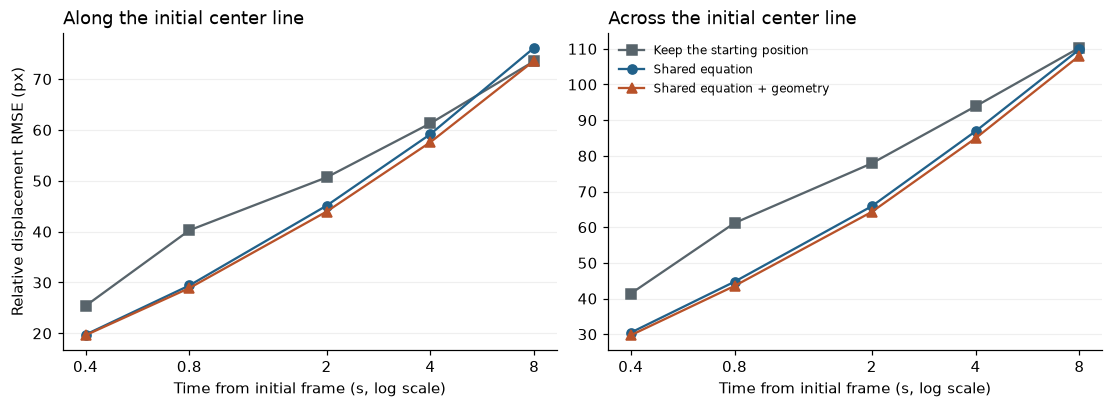

In [19]:
rollout = pd.read_csv(normal / "rollouts/pair_errors.csv").query("group == 'all'")
rollout_models = {"fixed": ("Keep the starting position", gray, "s"),
                  "shared_free": ("Shared equation", blue, "o"),
                  "shared_guarded": ("Shared equation + geometry", orange, "^")}
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
for ax, metric, title in zip(axes, ["normal_rmse_px", "tangent_rmse_px"],
                              ["Along the initial center line", "Across the initial center line"]):
    for key, (label, color, marker) in rollout_models.items():
        rows = rollout.loc[rollout.model.eq(key)].sort_values("seconds")
        ax.plot(rows.seconds, rows[metric], marker=marker, color=color, label=label)
    ax.set_xscale("log", base=2)
    ax.set_xticks(rows.seconds, [f"{t:g}" for t in rows.seconds])
    ax.set(title=title, xlabel="Time from initial frame (s, log scale)")
    ax.grid(axis="y", alpha=.2)
axes[0].set_ylabel("Relative displacement RMSE (px)")
axes[1].legend(fontsize=8)
plt.show()

The constrained equation improved both relative displacement components over holding position through **4 s**. At **8 s** its normal error was 73.62 px, essentially tied with 73.53 px for holding the starting position. Its tangential error was still slightly lower (108.05 versus 110.31 px).

**Which result to use.** For an impact question, use the event-level or reviewed clips and state how contact and the velocity windows were defined. For a trajectory forecast, use the gap, free motion and neighboring robots to predict the next step. The results here support stronger 0.4 s forecasts than estimates of individual rebound speeds. The reported equations and scores retain the pixel or body-diameter scale of their respective study. [Rollout scores](results/collision_transfer/preprocessed/pair_normal/rollouts/pair_errors.csv)